In [4]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import os
from pathlib import Path

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.2f}".format)

In [5]:
# 1/ data loading
data_path = Path("Documents/olist_sql_exercice")
orders = pd.read_csv(data_path / "olist_orders_dataset.csv")
customers = pd.read_csv(data_path / "olist_customers_dataset.csv")
order_items = pd.read_csv(data_path / "olist_order_items_dataset.csv")
products = pd.read_csv(data_path / "olist_products_dataset.csv")
sellers = pd.read_csv(data_path / "olist_sellers_dataset.csv")
payments = pd.read_csv(data_path / "olist_order_payments_dataset.csv")
reviews = pd.read_csv(data_path / "olist_order_reviews_dataset.csv")

In [6]:
# verify everything loaded correctly & show each table's shape
datasets = {
    "orders": orders,
    "customers": customers,
    "order_items": order_items,
    "products": products,
    "sellers": sellers,
    "payments": payments,
    "reviews": reviews
}

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]:,} rows × {df.shape[1]} columns")

orders: 99,441 rows × 8 columns
customers: 99,441 rows × 5 columns
order_items: 112,650 rows × 7 columns
products: 32,951 rows × 9 columns
sellers: 3,095 rows × 4 columns
payments: 103,886 rows × 5 columns
reviews: 99,224 rows × 7 columns


In [5]:
# 2/ structural inspection
for name, df in datasets.items():
    print(f"\n{'=' * 60}")
    print(f"TABLE: {name.upper()}")
    print(f"{'=' * 60}")

    print("\nFirst 5 rows:")
    display(df.head())

    print("\nData types and non-null counts:")
    df.info()


TABLE: ORDERS

First 5 rows:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00



Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

TABLE: CUSTOMERS

First 5 rows:


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP



Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB

TABLE: ORDER_ITEMS

First 5 rows:


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


... (5 outputs left out)

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45



Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  object 
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  object 
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 4.0+ MB

TABLE: REVIEWS

First 5 rows:


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53



Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


In [8]:
# 3/ statistical understanding 
# numerical variables
for name, df in datasets.items():
    print(f"\n{'=' * 60}")
    print(f"NUMERICAL SUMMARY: {name.upper()}")
    print(f"{'=' * 60}")

    display(df.describe().T)


NUMERICAL SUMMARY: ORDERS


,count,unique,top,freq
order_id,99441,99441,e481f51cbdc54678b7cc49136f2d6af7,1
customer_id,99441,99441,9ef432eb6251297304e76186b10a928d,1
order_status,99441,8,delivered,96478
order_purchase_timestamp,99441,98875,2018-08-02 12:05:26,3
order_approved_at,99281,90733,2018-02-27 04:31:10,9
order_delivered_carrier_date,97658,81018,2018-05-09 15:48:00,47
order_delivered_customer_date,96476,95664,2018-05-08 19:36:48,3
order_estimated_delivery_date,99441,459,2017-12-20 00:00:00,522



NUMERICAL SUMMARY: CUSTOMERS


,count,mean,std,min,25%,50%,75%,max
customer_zip_code_prefix,99441.00,35137.47,29797.94,1003.00,11347.00,24416.00,58900.00,99990.00



NUMERICAL SUMMARY: ORDER_ITEMS


,count,mean,std,min,25%,50%,75%,max
order_item_id,112650.00,1.20,0.71,1.00,1.00,1.00,1.00,21.00
price,112650.00,120.65,183.63,0.85,39.90,74.99,134.90,6735.00
freight_value,112650.00,19.99,15.81,0.00,13.08,16.26,21.15,409.68


... (4 outputs left out)


NUMERICAL SUMMARY: PAYMENTS


,count,mean,std,min,25%,50%,75%,max
payment_sequential,103886.00,1.09,0.71,1.00,1.00,1.00,1.00,29.00
payment_installments,103886.00,2.85,2.69,0.00,1.00,1.00,4.00,24.00
payment_value,103886.00,154.10,217.49,0.00,56.79,100.00,171.84,13664.08



NUMERICAL SUMMARY: REVIEWS


,count,mean,std,min,25%,50%,75%,max
review_score,99224.00,4.09,1.35,1.00,4.00,5.00,5.00,5.00


In [9]:
# categorial variables
for name, df in datasets.items():

    categorical_cols = df.select_dtypes(
        include=["object", "category"]
    ).columns

    print(f"\n{'=' * 60}")
    print(f"CATEGORICAL SUMMARY: {name.upper()}")
    print(f"{'=' * 60}")

    for col in categorical_cols:
        print(f"\nColumn: {col}")
        print("Unique values:", df[col].nunique())
        display(df[col].value_counts(dropna=False).head(10))


CATEGORICAL SUMMARY: ORDERS

Column: order_id
Unique values: 99441


order_id
e481f51cbdc54678b7cc49136f2d6af7    1
53cdb2fc8bc7dce0b6741e2150273451    1
47770eb9100c2d0c44946d9cf07ec65d    1
949d5b44dbf5de918fe9c16f97b45f8a    1
ad21c59c0840e6cb83a9ceb5573f8159    1
a4591c265e18cb1dcee52889e2d8acc3    1
136cce7faa42fdb2cefd53fdc79a6098    1
6514b8ad8028c9f2cc2374ded245783f    1
76c6e866289321a7c93b82b54852dc33    1
e69bfb5eb88e0ed6a785585b27e16dbf    1
Name: count, dtype: int64


Column: customer_id
Unique values: 99441


customer_id
9ef432eb6251297304e76186b10a928d    1
b0830fb4747a6c6d20dea0b8c802d7ef    1
41ce2a54c0b03bf3443c3d931a367089    1
f88197465ea7920adcdbec7375364d82    1
8ab97904e6daea8866dbdbc4fb7aad2c    1
503740e9ca751ccdda7ba28e9ab8f608    1
ed0271e0b7da060a393796590e7b737a    1
9bdf08b4b3b52b5526ff42d37d47f222    1
f54a9f0e6b351c431402b8461ea51999    1
31ad1d1b63eb9962463f764d4e6e0c9d    1
Name: count, dtype: int64


Column: order_status
Unique values: 8


order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

... (48 outputs left out)


Column: review_creation_date
Unique values: 636


review_creation_date
2017-12-19 00:00:00    463
2018-08-28 00:00:00    452
2017-12-20 00:00:00    440
2018-05-19 00:00:00    434
2018-05-15 00:00:00    425
2018-08-14 00:00:00    423
2018-03-29 00:00:00    421
2018-05-22 00:00:00    414
2018-05-04 00:00:00    412
2018-04-12 00:00:00    408
Name: count, dtype: int64


Column: review_answer_timestamp
Unique values: 98248


review_answer_timestamp
2017-06-15 23:21:05    4
2017-09-02 12:13:03    3
2018-02-26 15:53:18    3
2018-02-23 10:58:06    3
2018-03-21 01:02:05    3
2018-06-17 23:48:04    3
2017-09-05 12:12:51    3
2018-08-31 22:29:09    3
2017-02-14 13:58:48    3
2018-09-03 09:33:00    3
Name: count, dtype: int64

In [10]:
# 4/ missing_value assessment
missing_reports = {}
for name, df in datasets.items():

    missing_count = df.isnull().sum()
    missing_percentage = df.isnull().mean() * 100

    report = pd.DataFrame({
        "Missing Values": missing_count,
        "Missing Percentage": missing_percentage
    })

    report = report[report["Missing Values"] > 0]
    report = report.sort_values(
        by="Missing Percentage",
        ascending=False
    )

    missing_reports[name] = report

    print(f"\n{'=' * 60}")
    print(f"MISSING VALUES: {name.upper()}")
    print(f"{'=' * 60}")

    display(report)


MISSING VALUES: ORDERS


,Missing Values,Missing Percentage
order_delivered_customer_date,2965,2.98
order_delivered_carrier_date,1783,1.79
order_approved_at,160,0.16



MISSING VALUES: CUSTOMERS


,Missing Values,Missing Percentage



MISSING VALUES: ORDER_ITEMS


,Missing Values,Missing Percentage


... (4 outputs left out)


MISSING VALUES: PAYMENTS


,Missing Values,Missing Percentage



MISSING VALUES: REVIEWS


,Missing Values,Missing Percentage
review_comment_title,87656,88.34
review_comment_message,58247,58.70


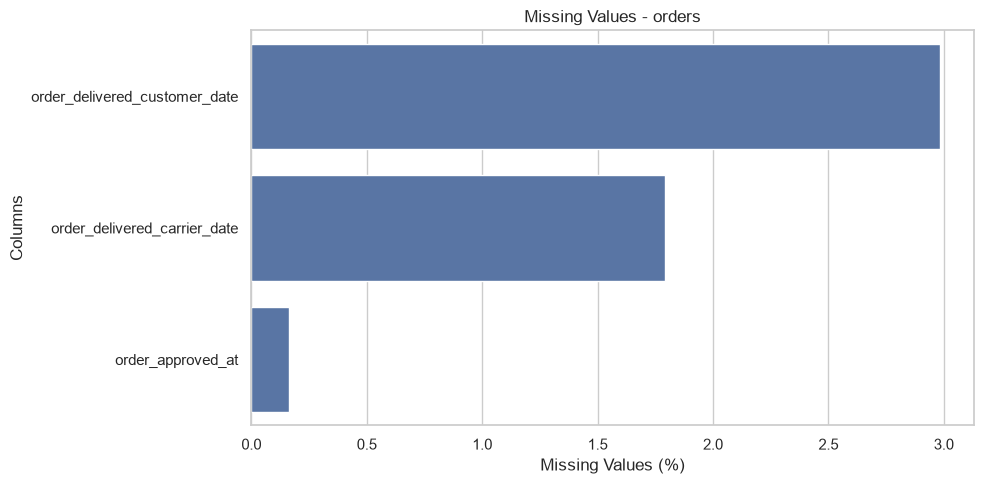

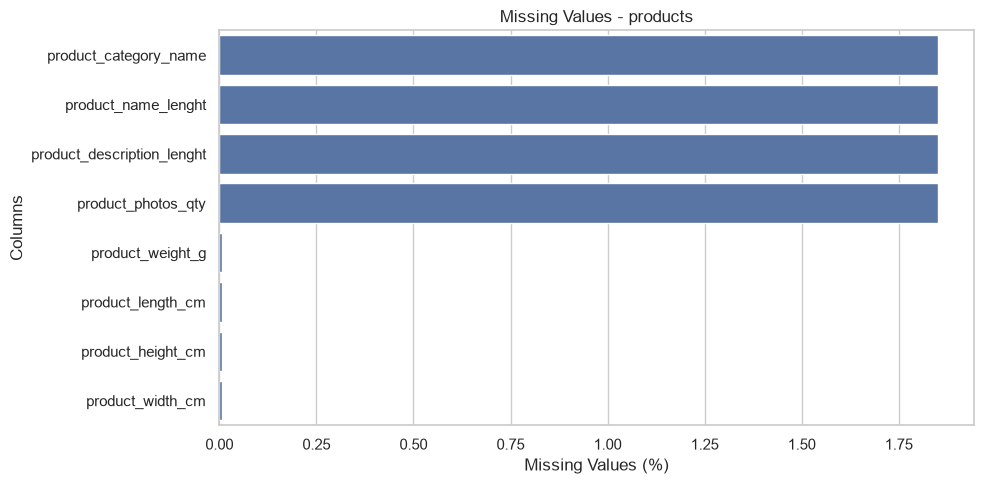

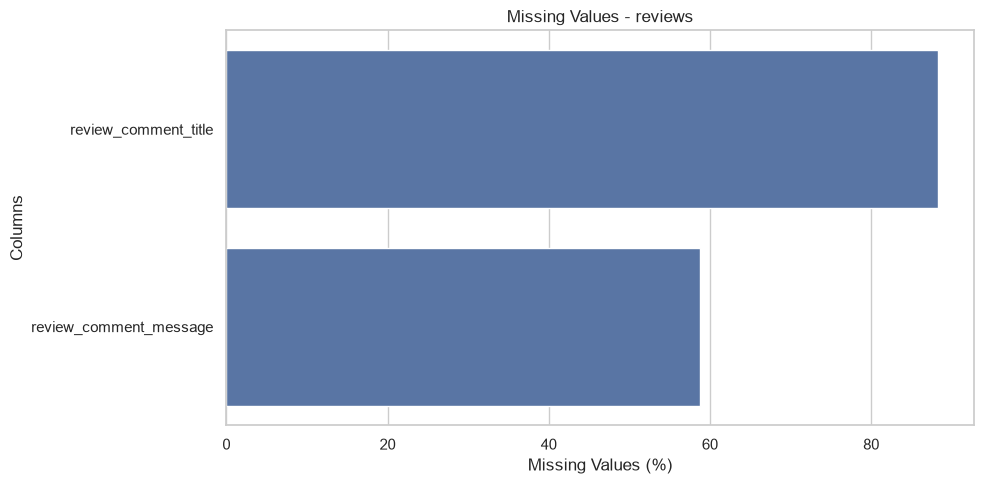

In [11]:
# visualizing missing values
import matplotlib.pyplot as plt
import seaborn as sns

for name, df in datasets.items():

    missing_percentage = (
        df.isnull().mean() * 100
    )

    missing_percentage = missing_percentage[
        missing_percentage > 0
    ].sort_values(ascending=False)

    if len(missing_percentage) == 0:
        continue

    plt.figure(figsize=(10, 5))

    sns.barplot(
        x=missing_percentage.values,
        y=missing_percentage.index
    )

    plt.title(f"Missing Values - {name}")
    plt.xlabel("Missing Values (%)")
    plt.ylabel("Columns")
    plt.tight_layout()
    plt.show()

In [12]:
# 5/ duplicate assessment
# completly duplicated rows
for name, df in datasets.items():

    duplicate_count = df.duplicated().sum()
    duplicate_percentage = (
        duplicate_count / len(df)
    ) * 100

    print(f"{name}:")
    print(f"Duplicate rows: {duplicate_count:,}")
    print(f"Duplicate percentage: {duplicate_percentage:.2f}%")
    print("-" * 40)

orders:
Duplicate rows: 0
Duplicate percentage: 0.00%
----------------------------------------
customers:
Duplicate rows: 0
Duplicate percentage: 0.00%
----------------------------------------
order_items:
Duplicate rows: 0
Duplicate percentage: 0.00%
----------------------------------------
products:
Duplicate rows: 0
Duplicate percentage: 0.00%
----------------------------------------
sellers:
Duplicate rows: 0
Duplicate percentage: 0.00%
----------------------------------------
payments:
Duplicate rows: 0
Duplicate percentage: 0.00%
----------------------------------------
reviews:
Duplicate rows: 0
Duplicate percentage: 0.00%
----------------------------------------


In [13]:
# duplicate primary_key candidates
primary_keys = {
    "orders": "order_id",
    "customers": "customer_id",
    "products": "product_id",
    "sellers": "seller_id",
    "reviews": "review_id"
}

for name, key in primary_keys.items():

    df = datasets[name]

    duplicate_count = df[key].duplicated().sum()

    print(f"{name} - {key}")
    print(f"Duplicated identifiers: {duplicate_count:,}")
    print("-" * 40)

orders - order_id
Duplicated identifiers: 0
----------------------------------------
customers - customer_id
Duplicated identifiers: 0
----------------------------------------
products - product_id
Duplicated identifiers: 0
----------------------------------------
sellers - seller_id
Duplicated identifiers: 0
----------------------------------------
reviews - review_id
Duplicated identifiers: 814
----------------------------------------


In [14]:
# 6/ data validity & consistency
# numerical columns with negative values
for name, df in datasets.items():

    numerical_cols = df.select_dtypes(
        include="number"
    ).columns

    print(f"\n{name.upper()}")

    for col in numerical_cols:

        negative_count = (df[col] < 0).sum()

        if negative_count > 0:
            print(
                f"{col}: {negative_count:,} negative values"
            )


ORDERS

CUSTOMERS

ORDER_ITEMS

PRODUCTS

SELLERS

PAYMENTS

REVIEWS


In [15]:
# date consistency
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

orders_dates = orders[date_columns].copy()

for col in date_columns:
    orders_dates[col] = pd.to_datetime(
        orders_dates[col],
        errors="coerce"
    )

print("Approval before purchase:")
print(
    (orders_dates["order_approved_at"] <
     orders_dates["order_purchase_timestamp"]).sum()
)

print("Carrier date before approval:")
print(
    (orders_dates["order_delivered_carrier_date"] <
     orders_dates["order_approved_at"]).sum()
)

print("Customer delivery before carrier:")
print(
    (orders_dates["order_delivered_customer_date"] <
     orders_dates["order_delivered_carrier_date"]).sum()
)

Approval before purchase:
0
Carrier date before approval:
1359
Customer delivery before carrier:
23


In [7]:
# 7/ outlier investigation
# calculate potential outliers using IQR (Interquartile Range)
outlier_columns = {
    "order_items": [
        "price",
        "freight_value"
    ],

    "products": [
        "product_weight_g",
        "product_length_cm",
        "product_height_cm",
        "product_width_cm",
        "product_photos_qty",
        "product_name_lenght",
        "product_description_lenght"
    ],

    "payments": [
        "payment_value",
        "payment_installments"
    ]
}

outlier_results = []

for table_name, columns in outlier_columns.items():

    df = datasets[table_name]

    for col in columns:

        if col not in df.columns:
            continue

        series = df[col].dropna()

        Q1 = series.quantile(0.25)
        Q3 = series.quantile(0.75)

        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = series[
            (series < lower_bound) |
            (series > upper_bound)
        ]

        outlier_results.append({
            "Table": table_name,
            "Column": col,
            "Q1": Q1,
            "Q3": Q3,
            "IQR": IQR,
            "Lower Bound": lower_bound,
            "Upper Bound": upper_bound,
            "Outlier Count": len(outliers),
            "Outlier Percentage": (
                len(outliers) / len(series) * 100
            ),
            "Minimum": series.min(),
            "Maximum": series.max()
        })

outlier_report = pd.DataFrame(outlier_results)

display(
    outlier_report.round(2)
)

,Table,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage,Minimum,Maximum
0,order_items,price,39.90,134.90,95.00,-102.60,277.40,8427,7.48,0.85,6735.00
1,order_items,freight_value,13.08,21.15,8.07,0.98,33.25,12134,10.77,0.00,409.68
2,products,product_weight_g,300.00,1900.00,1600.00,-2100.00,4300.00,4551,13.81,0.00,40425.00
3,products,product_length_cm,18.00,38.00,20.00,-12.00,68.00,1380,4.19,7.00,105.00
4,products,product_height_cm,8.00,21.00,13.00,-11.50,40.50,1892,5.74,2.00,105.00
5,products,product_width_cm,15.00,30.00,15.00,-7.50,52.50,912,2.77,6.00,118.00
6,products,product_photos_qty,1.00,3.00,2.00,-2.00,6.00,849,2.63,1.00,20.00
7,products,product_name_lenght,42.00,57.00,15.00,19.50,79.50,290,0.90,5.00,76.00
8,products,product_description_lenght,339.00,972.00,633.00,-610.50,1921.50,2078,6.43,4.00,3992.00
9,payments,payment_value,56.79,171.84,115.05,-115.78,344.41,7981,7.68,0.00,13664.08


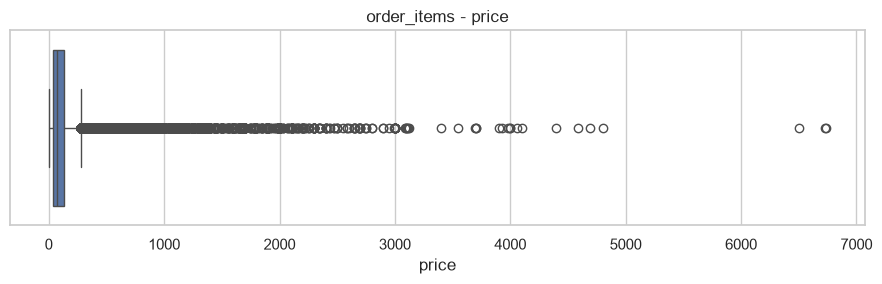

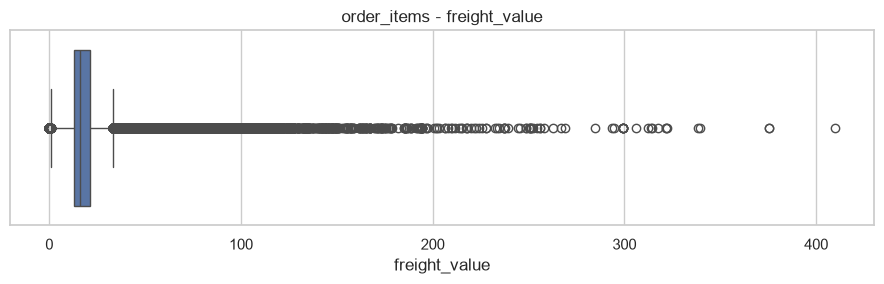

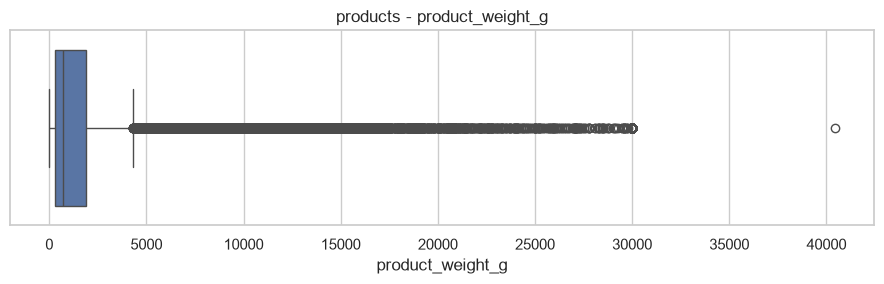

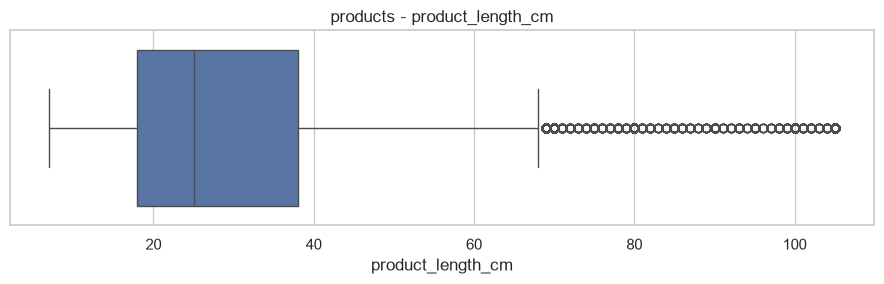

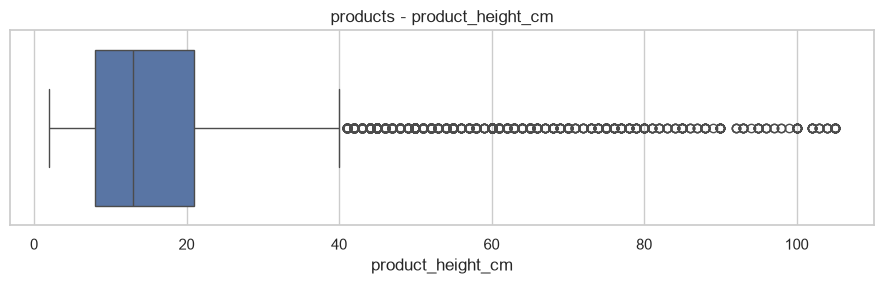

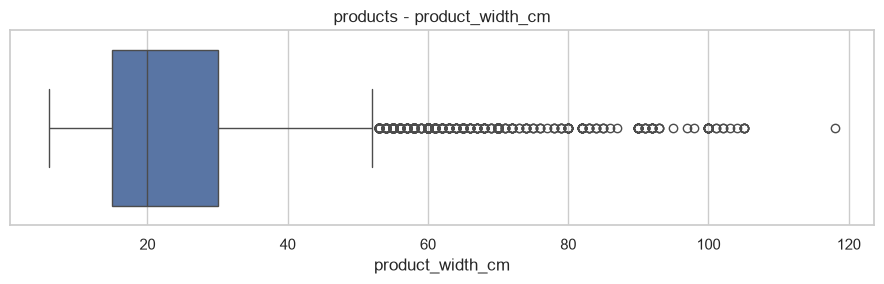

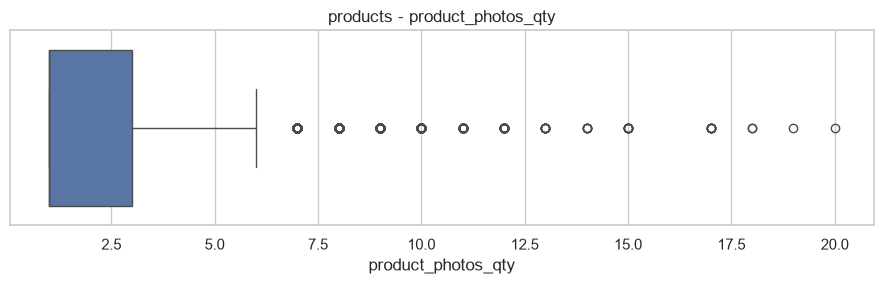

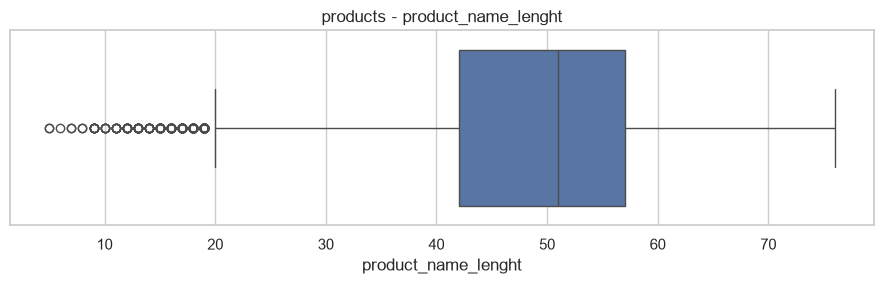

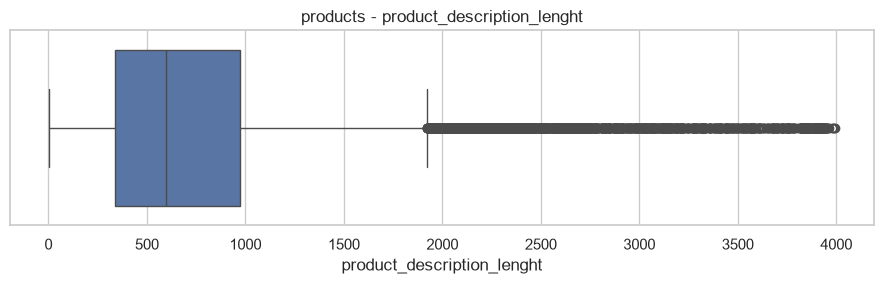

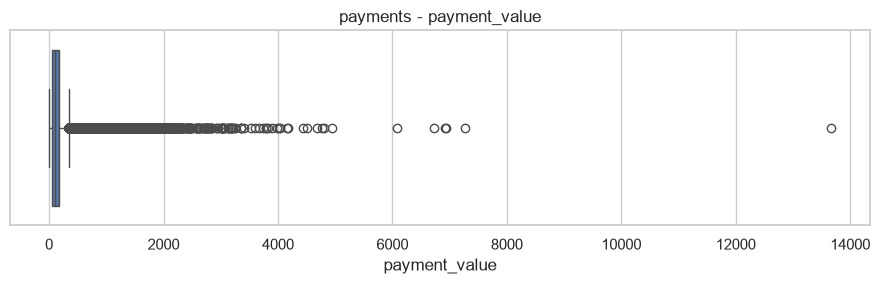

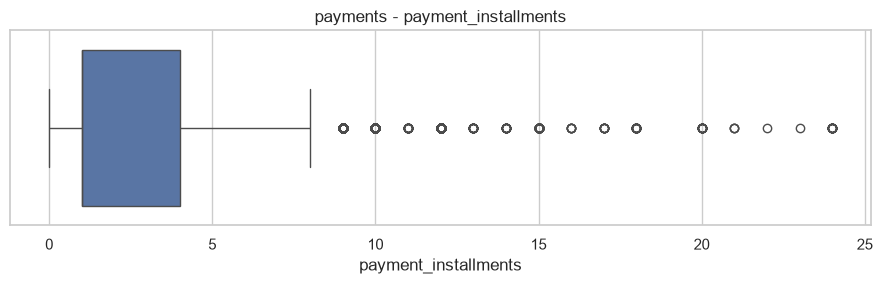

In [8]:
for table_name, columns in outlier_columns.items():

    df = datasets[table_name]

    for col in columns:

        if col not in df.columns:
            continue

        plt.figure(figsize=(9, 3))

        sns.boxplot(x=df[col])

        plt.title(f"{table_name} - {col}")
        plt.xlabel(col)

        plt.tight_layout()
        plt.show()

In [17]:
# investigating the actual outlier records
# price
price = order_items["price"]

Q1 = price.quantile(0.25)
Q3 = price.quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

price_outliers = order_items[
    order_items["price"] > upper_bound
].sort_values(
    by="price",
    ascending=False
)

display(price_outliers.head(20))

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
3556,0812eb902a67711a1cb742b3cdaa65ae,1,489ae2aa008f021502940f251d4cce7f,e3b4998c7a498169dc7bce44e6bb6277,2017-02-16 20:37:36,6735.00,194.31
112233,fefacc66af859508bf1a7934eab1e97f,1,69c590f7ffc7bf8db97190b6cb6ed62e,80ceebb4ee9b31afb6c6a916a574a1e2,2018-08-02 04:05:13,6729.00,193.21
107841,f5136e38d1a14a4dbd87dff67da82701,1,1bdf5e6731585cf01aa8169c7028d6ad,ee27a8f15b1dded4d213a468ba4eb391,2017-06-15 02:45:17,6499.00,227.66
74336,a96610ab360d42a2e5335a3998b4718a,1,a6492cc69376c469ab6f61d8f44de961,59417c56835dd8e2e72f91f809cd4092,2017-04-18 13:25:18,4799.00,151.34
11249,199af31afc78c699f0dbf71fb178d4d4,1,c3ed642d592594bb648ff4a04cee2747,59417c56835dd8e2e72f91f809cd4092,2017-05-09 15:50:15,4690.00,74.34
62086,8dbc85d1447242f3b127dda390d56e19,1,259037a6a41845e455183f89c5035f18,c72de06d72748d1a0dfb2125be43ba63,2018-06-28 12:36:36,4590.00,91.78
29193,426a9742b533fc6fed17d1fd6d143d7e,1,a1beef8f3992dbd4cd8726796aa69c53,512d298ac2a96d1931b6bd30aa21f61d,2018-08-16 14:24:28,4399.87,113.45
45843,68101694e5c5dc7330c91e1bbc36214f,1,6cdf8fc1d741c76586d8b6b15e9eef30,ed4acab38528488b65a9a9c603ff024a,2018-04-05 08:27:27,4099.99,75.27
78310,b239ca7cd485940b31882363b52e6674,1,dd113cb02b2af9c8e5787e8f1f0722f6,821fb029fc6e495ca4f08a35d51e53a5,2018-08-02 08:15:14,4059.00,104.51
59137,86c4eab1571921a6a6e248ed312f5a5a,1,6902c1962dd19d540807d0ab8fade5c6,fa1c13f2614d7b5c4749cbc52fecda94,2017-03-23 20:08:04,3999.90,17.01


In [18]:
# impossible or suspicious values
positive_columns = {
    "order_items": [
        "price",
        "freight_value"
    ],

    "products": [
        "product_weight_g",
        "product_length_cm",
        "product_height_cm",
        "product_width_cm"
    ],

    "payments": [
        "payment_value"
    ]
}

for table_name, columns in positive_columns.items():

    df = datasets[table_name]

    print(f"\n{'=' * 50}")
    print(table_name.upper())
    print(f"{'=' * 50}")

    for col in columns:

        if col not in df.columns:
            continue

        negative_count = (df[col] < 0).sum()
        zero_count = (df[col] == 0).sum()

        print(f"\n{col}")
        print(f"Negative values: {negative_count:,}")
        print(f"Zero values: {zero_count:,}")


ORDER_ITEMS

price
Negative values: 0
Zero values: 0

freight_value
Negative values: 0
Zero values: 383

PRODUCTS

product_weight_g
Negative values: 0
Zero values: 4

product_length_cm
Negative values: 0
Zero values: 0

product_height_cm
Negative values: 0
Zero values: 0

product_width_cm
Negative values: 0
Zero values: 0

PAYMENTS

payment_value
Negative values: 0
Zero values: 9


In [18]:
# referential integrity
relationships = [
    ("orders", "customer_id", "customers", "customer_id"),
    ("order_items", "order_id", "orders", "order_id"),
    ("order_items", "product_id", "products", "product_id"),
    ("order_items", "seller_id", "sellers", "seller_id"),
    ("payments", "order_id", "orders", "order_id"),
    ("reviews", "order_id", "orders", "order_id")
]

for child_table, child_col, parent_table, parent_col in relationships:

    child = datasets[child_table]
    parent = datasets[parent_table]

    orphan_count = (
        ~child[child_col].isin(parent[parent_col])
        & child[child_col].notna()
    ).sum()

    print(
        f"{child_table}.{child_col} -> "
        f"{parent_table}.{parent_col}: "
        f"{orphan_count:,} orphan records"
    )

orders.customer_id -> customers.customer_id: 0 orphan records
order_items.order_id -> orders.order_id: 0 orphan records
order_items.product_id -> products.product_id: 0 orphan records
order_items.seller_id -> sellers.seller_id: 0 orphan records
payments.order_id -> orders.order_id: 0 orphan records
reviews.order_id -> orders.order_id: 0 orphan records


In [11]:
# are missing order timestamps related to order status?
date_columns = [
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date"
]

for col in date_columns:

    print(f"\nMissing {col} by order status:")

    display(
        orders.loc[
            orders[col].isna(), "order_status"
        ].value_counts(dropna=False)
    )


Missing order_approved_at by order status:


order_status
canceled     141
delivered     14
created        5
Name: count, dtype: int64


Missing order_delivered_carrier_date by order status:


order_status
unavailable    609
canceled       550
invoiced       314
processing     301
created          5
approved         2
delivered        2
Name: count, dtype: int64


Missing order_delivered_customer_date by order status:


order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

In [12]:
# do the missing product attributes belong to the same products?
product_missing_cols = [
    "product_category_name",
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty"
]

print("Number of missing attributes per product:")

display(
    products[product_missing_cols]
    .isna()
    .sum(axis=1)
    .value_counts()
    .sort_index()
)

Number of missing attributes per product:


0    32341
4      610
Name: count, dtype: int64

In [13]:
# investigating duplicated review IDs
duplicated_reviews = reviews[
    reviews["review_id"].duplicated(keep=False)
].sort_values("review_id")

print("Rows involved in duplicated review IDs:",
      len(duplicated_reviews))

print("Distinct duplicated review IDs:",
      duplicated_reviews["review_id"].nunique())

display(duplicated_reviews.head(10))

Rows involved in duplicated review IDs: 1603
Distinct duplicated review IDs: 789


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
54832,017808d29fd1f942d97e50184dfb4c13,8daaa9e99d60fbba579cc1c3e3bfae01,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
99167,017808d29fd1f942d97e50184dfb4c13,b1461c8882153b5fe68307c46a506e39,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44


In [14]:
# validating review scores and payment installments
print("Review score distribution:")

display(
    reviews["review_score"]
    .value_counts(dropna=False)
    .sort_index()
)

invalid_scores = reviews[
    reviews["review_score"].notna()
    & ~reviews["review_score"].between(1, 5)
]

print("Invalid review scores:", len(invalid_scores))

print("\nZero payment installments:",
      (payments["payment_installments"] == 0).sum())

print("Negative payment installments:",
      (payments["payment_installments"] < 0).sum())

Review score distribution:


review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

Invalid review scores: 0

Zero payment installments: 2
Negative payment installments: 0


In [20]:
duplicated_reviews = reviews[
    reviews["review_id"].duplicated(keep=False)
].sort_values("review_id")

print(f"Rows involved: {len(duplicated_reviews):,}")
print(f"Distinct duplicated IDs: {duplicated_reviews['review_id'].nunique():,}")

display(duplicated_reviews.head(20))

Rows involved: 1,603
Distinct duplicated IDs: 789


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
54832,017808d29fd1f942d97e50184dfb4c13,8daaa9e99d60fbba579cc1c3e3bfae01,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
99167,017808d29fd1f942d97e50184dfb4c13,b1461c8882153b5fe68307c46a506e39,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44


In [23]:
# 1. extract all rows with duplicated review IDs
duplicated_reviews = reviews[
    reviews["review_id"].duplicated(keep=False)
].copy()

# 2. count distinct combinations of review text per review ID
review_text_counts = (
    duplicated_reviews
    .groupby("review_id")[
        ["review_score", "review_comment_title", "review_comment_message"]
    ]
    .apply(lambda group: group.drop_duplicates().shape[0])
)
# 3. count duplicated IDs with identical review text
identical_text_count = (review_text_counts == 1).sum()

# 4. count duplicated IDs with different review text
different_text_count = (review_text_counts > 1).sum()

# 5. display results
print(f"Total duplicated review IDs: {len(review_text_counts):,}")
print(f"Duplicated IDs with identical review text: {identical_text_count:,}")
print(f"Duplicated IDs with different review text: {different_text_count:,}")

Total duplicated review IDs: 789
Duplicated IDs with identical review text: 789
Duplicated IDs with different review text: 0


In [27]:
delivered_missing_approval = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_approved_at"].isna())
]

display(delivered_missing_approval)

delivered_missing_carrier = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_delivered_carrier_date"].isna())
]

display(delivered_missing_carrier)

delivered_missing_customer = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_delivered_customer_date"].isna())
]

display(delivered_missing_customer)

suspicious_delivered_orders = orders[
    (orders["order_status"] == "delivered") &
    (
        orders["order_approved_at"].isna() |
        orders["order_delivered_carrier_date"].isna() |
        orders["order_delivered_customer_date"].isna()
    )
].copy()

print(f"Total affected delivered orders: {len(suspicious_delivered_orders)}")

display(
    suspicious_delivered_orders[
        [
            "order_id",
            "order_status",
            "order_purchase_timestamp",
            "order_approved_at",
            "order_delivered_carrier_date",
            "order_delivered_customer_date",
            "order_estimated_delivery_date"
        ]
    ]
)




,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
5323,e04abd8149ef81b95221e88f6ed9ab6a,2127dc6603ac33544953ef05ec155771,delivered,2017-02-18 14:40:00,NaN,2017-02-23 12:04:47,2017-03-01 13:25:33,2017-03-17 00:00:00
16567,8a9adc69528e1001fc68dd0aaebbb54a,4c1ccc74e00993733742a3c786dc3c1f,delivered,2017-02-18 12:45:31,NaN,2017-02-23 09:01:52,2017-03-02 10:05:06,2017-03-21 00:00:00
19031,7013bcfc1c97fe719a7b5e05e61c12db,2941af76d38100e0f8740a374f1a5dc3,delivered,2017-02-18 13:29:47,NaN,2017-02-22 16:25:25,2017-03-01 08:07:38,2017-03-17 00:00:00
22663,5cf925b116421afa85ee25e99b4c34fb,29c35fc91fc13fb5073c8f30505d860d,delivered,2017-02-18 16:48:35,NaN,2017-02-22 11:23:10,2017-03-09 07:28:47,2017-03-31 00:00:00
23156,12a95a3c06dbaec84bcfb0e2da5d228a,1e101e0daffaddce8159d25a8e53f2b2,delivered,2017-02-17 13:05:55,NaN,2017-02-22 11:23:11,2017-03-02 11:09:19,2017-03-20 00:00:00
26800,c1d4211b3dae76144deccd6c74144a88,684cb238dc5b5d6366244e0e0776b450,delivered,2017-01-19 12:48:08,NaN,2017-01-25 14:56:50,2017-01-30 18:16:01,2017-03-01 00:00:00
38290,d69e5d356402adc8cf17e08b5033acfb,68d081753ad4fe22fc4d410a9eb1ca01,delivered,2017-02-19 01:28:47,NaN,2017-02-23 03:11:48,2017-03-02 03:41:58,2017-03-27 00:00:00
39334,d77031d6a3c8a52f019764e68f211c69,0bf35cac6cc7327065da879e2d90fae8,delivered,2017-02-18 11:04:19,NaN,2017-02-23 07:23:36,2017-03-02 16:15:23,2017-03-22 00:00:00
48401,7002a78c79c519ac54022d4f8a65e6e8,d5de688c321096d15508faae67a27051,delivered,2017-01-19 22:26:59,NaN,2017-01-27 11:08:05,2017-02-06 14:22:19,2017-03-16 00:00:00
61743,2eecb0d85f281280f79fa00f9cec1a95,a3d3c38e58b9d2dfb9207cab690b6310,delivered,2017-02-17 17:21:55,NaN,2017-02-22 11:42:51,2017-03-03 12:16:03,2017-03-20 00:00:00


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
73222,2aa91108853cecb43c84a5dc5b277475,afeb16c7f46396c0ed54acb45ccaaa40,delivered,2017-09-29 08:52:58,2017-09-29 09:07:16,NaN,2017-11-20 19:44:47,2017-11-14 00:00:00
92643,2d858f451373b04fb5c984a1cc2defaf,e08caf668d499a6d643dafd7c5cc498a,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaN,NaN,2017-06-23 00:00:00


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,ec05a6d8558c6455f0cbbd8a420ad34f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaN,2017-12-18 00:00:00
20618,f5dd62b788049ad9fc0526e3ad11a097,5e89028e024b381dc84a13a3570decb4,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaN,2018-07-16 00:00:00
43834,2ebdfc4f15f23b91474edf87475f108e,29f0540231702fda0cfdee0a310f11aa,delivered,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
79263,e69f75a717d64fc5ecdfae42b2e8e086,cfda40ca8dd0a5d486a9635b611b398a,delivered,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
82868,0d3268bad9b086af767785e3f0fc0133,4f1d63d35fb7c8999853b2699f5c7649,delivered,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaN,2018-07-24 00:00:00
92643,2d858f451373b04fb5c984a1cc2defaf,e08caf668d499a6d643dafd7c5cc498a,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaN,NaN,2017-06-23 00:00:00
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,dd1b84a7286eb4524d52af4256c0ba24,delivered,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaN,2018-06-26 00:00:00
98038,20edc82cf5400ce95e1afacc25798b31,28c37425f1127d887d7337f284080a0f,delivered,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaN,2018-07-19 00:00:00


Total affected delivered orders: 23


,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaN,2017-12-18 00:00:00
5323,e04abd8149ef81b95221e88f6ed9ab6a,delivered,2017-02-18 14:40:00,NaN,2017-02-23 12:04:47,2017-03-01 13:25:33,2017-03-17 00:00:00
16567,8a9adc69528e1001fc68dd0aaebbb54a,delivered,2017-02-18 12:45:31,NaN,2017-02-23 09:01:52,2017-03-02 10:05:06,2017-03-21 00:00:00
19031,7013bcfc1c97fe719a7b5e05e61c12db,delivered,2017-02-18 13:29:47,NaN,2017-02-22 16:25:25,2017-03-01 08:07:38,2017-03-17 00:00:00
20618,f5dd62b788049ad9fc0526e3ad11a097,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaN,2018-07-16 00:00:00
22663,5cf925b116421afa85ee25e99b4c34fb,delivered,2017-02-18 16:48:35,NaN,2017-02-22 11:23:10,2017-03-09 07:28:47,2017-03-31 00:00:00
23156,12a95a3c06dbaec84bcfb0e2da5d228a,delivered,2017-02-17 13:05:55,NaN,2017-02-22 11:23:11,2017-03-02 11:09:19,2017-03-20 00:00:00
26800,c1d4211b3dae76144deccd6c74144a88,delivered,2017-01-19 12:48:08,NaN,2017-01-25 14:56:50,2017-01-30 18:16:01,2017-03-01 00:00:00
38290,d69e5d356402adc8cf17e08b5033acfb,delivered,2017-02-19 01:28:47,NaN,2017-02-23 03:11:48,2017-03-02 03:41:58,2017-03-27 00:00:00
39334,d77031d6a3c8a52f019764e68f211c69,delivered,2017-02-18 11:04:19,NaN,2017-02-23 07:23:36,2017-03-02 16:15:23,2017-03-22 00:00:00


In [28]:
zero_installments = payments[
    payments["payment_installments"] == 0
]

print(f"Records with zero installments: {len(zero_installments)}")

display(zero_installments)


Records with zero installments: 2


,order_id,payment_sequential,payment_type,payment_installments,payment_value
46982,744bade1fcf9ff3f31d860ace076d422,2,credit_card,0,58.69
79014,1a57108394169c0b47d8f876acc9ba2d,2,credit_card,0,129.94


In [29]:
zero_payments = payments[
    payments["payment_value"] == 0
]

print(f"Records with zero payment value: {len(zero_payments)}")

display(zero_payments)

Records with zero payment value: 9


,order_id,payment_sequential,payment_type,payment_installments,payment_value
19922,8bcbe01d44d147f901cd3192671144db,4,voucher,1,0.00
36822,fa65dad1b0e818e3ccc5cb0e39231352,14,voucher,1,0.00
43744,6ccb433e00daae1283ccc956189c82ae,4,voucher,1,0.00
51280,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.00
57411,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.00
62674,45ed6e85398a87c253db47c2d9f48216,3,voucher,1,0.00
77885,fa65dad1b0e818e3ccc5cb0e39231352,13,voucher,1,0.00
94427,c8c528189310eaa44a745b8d9d26908b,1,not_defined,1,0.00
100766,b23878b3e8eb4d25a158f57d96331b18,4,voucher,1,0.00


In [30]:
zero_payment_orders = zero_payments["order_id"].unique()

related_zero_payment_orders = payments[
    payments["order_id"].isin(zero_payment_orders)
].sort_values(["order_id", "payment_sequential"])

display(related_zero_payment_orders)

,order_id,payment_sequential,payment_type,payment_installments,payment_value
57411,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.00
33781,45ed6e85398a87c253db47c2d9f48216,1,voucher,1,21.13
11755,45ed6e85398a87c253db47c2d9f48216,2,voucher,1,50.01
62674,45ed6e85398a87c253db47c2d9f48216,3,voucher,1,0.00
51280,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.00
40546,6ccb433e00daae1283ccc956189c82ae,1,credit_card,5,84.67
93478,6ccb433e00daae1283ccc956189c82ae,2,voucher,1,14.65
92318,6ccb433e00daae1283ccc956189c82ae,3,voucher,1,22.72
43744,6ccb433e00daae1283ccc956189c82ae,4,voucher,1,0.00
20963,8bcbe01d44d147f901cd3192671144db,1,credit_card,1,36.21


In [31]:
zero_weight_products = products[
    products["product_weight_g"] == 0
]

print(f"Products with zero weight: {len(zero_weight_products)}")

display(zero_weight_products)

Products with zero weight: 4


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
9769,81781c0fed9fe1ad6e8c81fca1e1cb08,cama_mesa_banho,51.00,529.00,1.00,0.00,30.00,25.00,30.00
13683,8038040ee2a71048d4bdbbdc985b69ab,cama_mesa_banho,48.00,528.00,1.00,0.00,30.00,25.00,30.00
14997,36ba42dd187055e1fbe943b2d11430ca,cama_mesa_banho,53.00,528.00,1.00,0.00,30.00,25.00,30.00
32079,e673e90efa65a5409ff4196c038bb5af,cama_mesa_banho,53.00,528.00,1.00,0.00,30.00,25.00,30.00
